# 03 Variables

Pour chaque cohorte du notebook 01, une ligne par artiste de la population, avec sa cible y et des variables regroupées en familles (`src/transformation.py`). Chaque variable n'utilise que ce que la base savait à T0. Ce sont les sorties ajoutées avant T0, et les labels, supports et liens créés avant T0. Comme pour les sorties, leur date de création s'estime grâce aux id croissants (`date_creation`). Le statut en major de ces sorties est lui aussi recalculé avec la base de T0 (`vue_de_t0`, partie 9).

Les graphiques et les décisions n'utilisent que les cohortes d'entraînement (T0 = 2014 à 2018). La cohorte de test (T0 = 2021) n'est calculée qu'à la fin, pour la table finale.

In [1]:
import sys
from unittest.mock import patch

import matplotlib.pyplot as plt
import pandas as pd

sys.path.append("..")
import src.transformation as transformation
from src.modelisation import auc
from src.transformation import (
    ECARTEES, HOLDINGS, activite, cohorte, documentation, label, labels_des_sorties, liens_labels_crees, lire, marche,
    membres, profil, proximite, recentes, reseau, sorties_du_projet, traction, variables, vue_de_t0,
)

ENTRAINEMENT, TEST = [2014, 2015, 2016, 2017, 2018], 2021

sorties = sorties_du_projet()
vues = {t0: vue_de_t0(sorties, t0) for t0 in ENTRAINEMENT}

In [2]:
def par_cohorte(famille, **options):
    tables = {t0: cohorte(sorties, t0).rename("y").to_frame().join(famille(vues[t0], t0, **options)) for t0 in ENTRAINEMENT}
    return pd.concat(tables, names=["t0", "artist"])


def taux_par_groupe(x, y):
    """% de positifs par groupe de x : ses valeurs s'il en a peu (bornées aux centiles 1 et 99),
    sinon ses déciles, sans couper les ex aequo, ou 5 tranches de même largeur si les ex aequo
    laissent moins de 4 déciles. Les valeurs manquantes sont mises à part."""
    if pd.api.types.is_bool_dtype(x) or not pd.api.types.is_numeric_dtype(x):
        return 100 * y.groupby(x, observed=True).mean()
    bas, haut = x.quantile(0.01), x.quantile(0.99)
    bornee = x.clip(bas, haut)
    if bornee.nunique() <= 12:
        taux = 100 * y.groupby(bornee).mean()
        etiquettes = [f"{v:g}" for v in taux.index]
        if x.min() < bas:
            etiquettes[0] = f"≤ {bas:g}"
        if x.max() > haut:
            etiquettes[-1] = f"≥ {haut:g}"
    else:
        groupes = pd.qcut(x, 10, duplicates="drop")
        if len(groupes.cat.categories) < 4:
            groupes = pd.cut(bornee, 5)
        taux = 100 * y.groupby(groupes, observed=True).mean()
        etiquettes = [f"≤ {i.right:.4g}" for i in taux.index]
    taux.index = etiquettes
    return taux


def resume(table):
    lignes = {}
    for colonne in table.drop(columns="y").select_dtypes(["number", "bool"]).columns:
        x = table[colonne]
        taux = taux_par_groupe(x, table["y"])
        lignes[colonne] = {
            "renseignée": x.notna().mean(),
            "non nulle": (x.fillna(0) != 0).mean(),
            "AUC": auc(x, table["y"]),
            "% en bas": taux.iloc[0],
            "% en haut": taux.iloc[-1],
        }
    return pd.DataFrame(lignes).T.round(3)


def graphiques(table, colonnes):
    lignes, par_ligne = (len(colonnes) + 3) // 4, min(len(colonnes), 4)
    fig, axes = plt.subplots(lignes, par_ligne, figsize=(4 * par_ligne, 3.2 * lignes + 0.4), squeeze=False)
    for ax, colonne in zip(axes.flat, colonnes):
        x = table[colonne]
        taux = taux_par_groupe(x, table["y"])
        if x.isna().any():
            taux["manquant"] = 100 * table.loc[x.isna(), "y"].mean()
        taux.plot.bar(ax=ax, color="tab:blue", title=colonne, xlabel="")
        ax.axhline(100 * table["y"].mean(), color="grey", linestyle="--")
    for ax in axes.flat[len(colonnes):]:
        ax.axis("off")
    axes[0, 0].set_ylabel("% de positifs")
    fig.suptitle("% de positifs par groupe, en pointillés le taux moyen")
    plt.tight_layout()
    plt.show()

## 1. Activité

Un artiste qui sort beaucoup, surtout des singles, et de plus en plus, est peut-être en train de percer.

257807 lignes, 1.06% de positifs


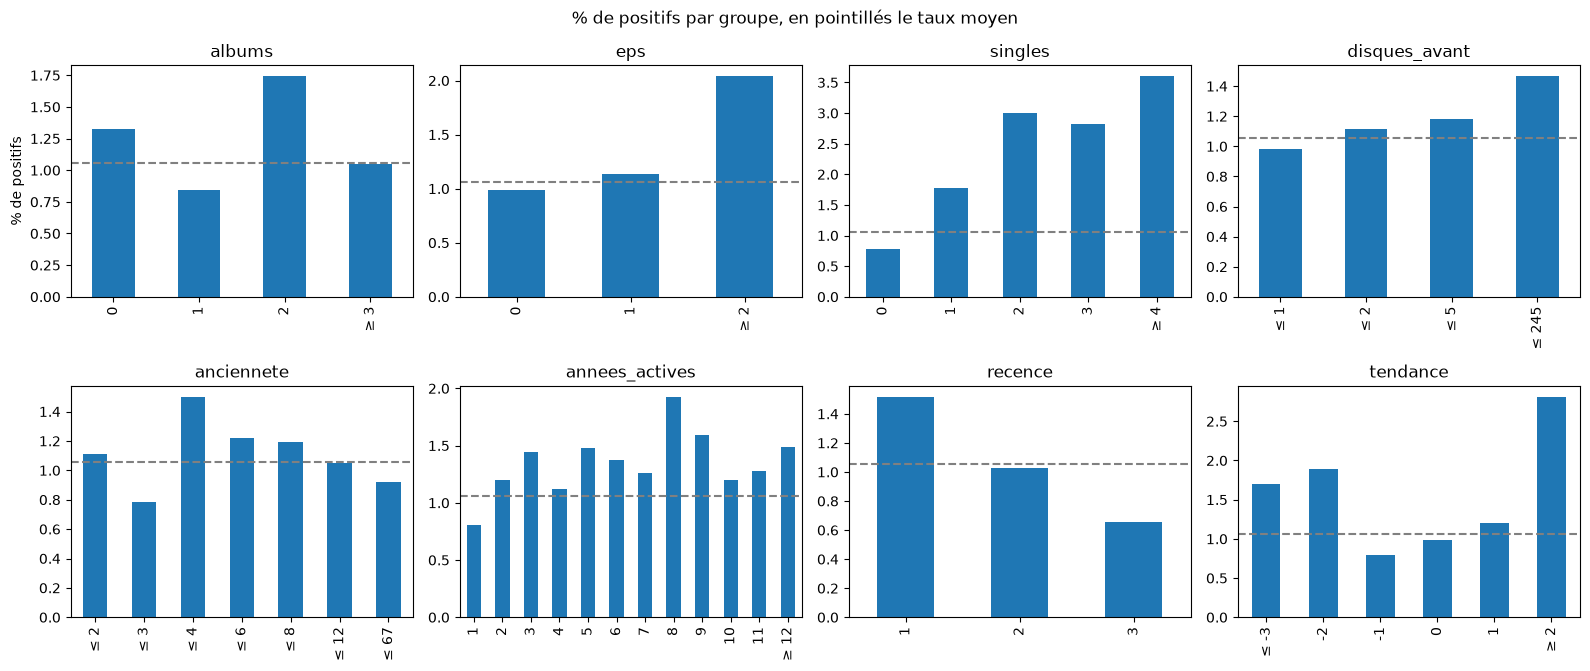

,renseignée,non nulle,AUC,% en bas,% en haut
albums,1.0,0.692,0.479,1.326,1.048
eps,1.0,0.258,0.529,0.986,2.039
singles,1.0,0.206,0.614,0.772,3.600
disques_avant,1.0,0.430,0.529,0.985,1.465
anciennete,1.0,1.000,0.497,1.110,0.918
annees_actives,1.0,1.000,0.566,0.804,1.488
recence,1.0,1.000,0.410,1.517,0.654
tendance,1.0,0.662,0.539,1.698,2.812


In [3]:
act = par_cohorte(activite)
print(f"{len(act)} lignes, {act['y'].mean():.2%} de positifs")
graphiques(act, act.columns.drop("y"))
resume(act)

Les singles portent le plus de signal (AUC 0,614). On passe de 0,77 % de positifs sans single en 3 ans à 3,60 % à partir de 4. La récence aussi (AUC 0,410, soit 0,590 dans l'autre sens). Une dernière sortie l'an dernier donne 1,52 % de positifs, une sortie vieille de 3 ans 0,65 %. Albums et ancienneté ont une AUC proche de 0,5 (0,479 et 0,497), mais leurs graphiques ne sont pas plats, on les garde aussi.

## 2. Traction

Un disque sorti en plusieurs éditions, dans plusieurs pays ou sur un support physique a sans doute déjà un public.

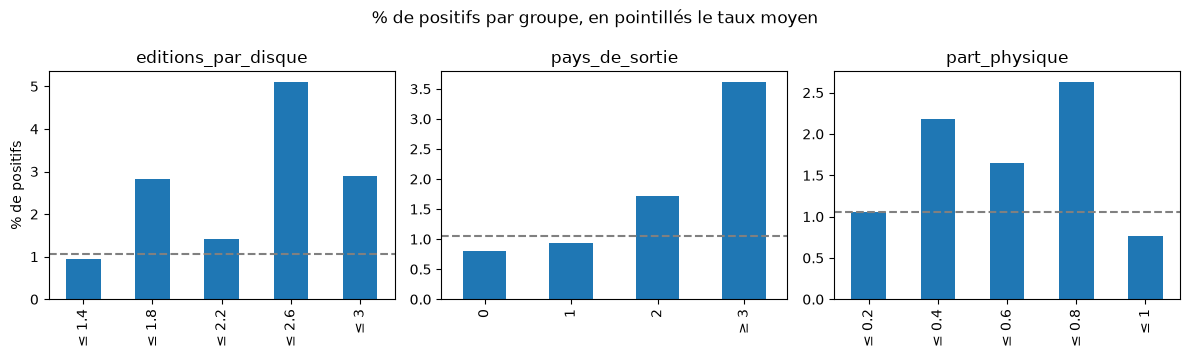

,renseignée,non nulle,AUC,% en bas,% en haut
editions_par_disque,1.0,1.000,0.560,0.950,2.894
pays_de_sortie,1.0,0.900,0.563,0.798,3.611
part_physique,1.0,0.484,0.480,1.057,0.764


In [4]:
tra = par_cohorte(traction)
graphiques(tra, tra.columns.drop("y"))
resume(tra)

Sortir dans plusieurs pays est le signal le plus net (AUC 0,563). On passe de 0,80 % de positifs sans pays connu à 3,61 % à partir de 3 pays. Les éditions par disque vont dans le même sens (AUC 0,560). La part d'éditions physiques n'est pas monotone (AUC 0,480). Elle donne 1,06 % de positifs sous 20 %, 0,76 % au-dessus de 80 % et plus entre les deux.

Les pays de sortie sont ceux d'aujourd'hui, `release_country` n'a pas de date.

## 3. Documentation

Les sorties d'un artiste suivi de près arrivent-elles plus vite dans la base ?

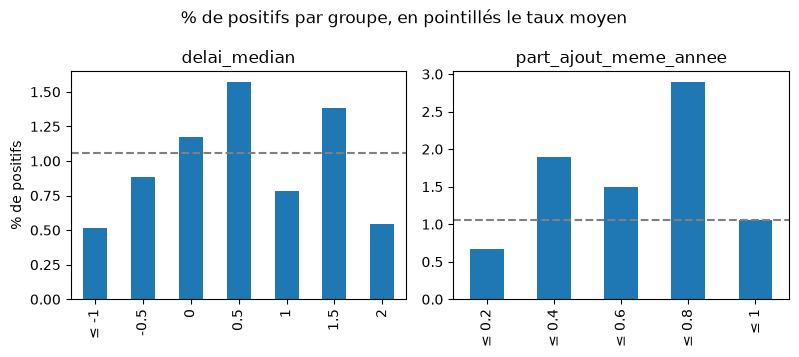

,renseignée,non nulle,AUC,% en bas,% en haut
delai_median,1.0,0.362,0.464,0.514,0.545
part_ajout_meme_annee,1.0,0.734,0.517,0.669,1.057


In [5]:
doc = par_cohorte(documentation)
graphiques(doc, doc.columns.drop("y"))
resume(doc)

Signal faible et non monotone (AUC 0,464 et 0,517). Le délai est borné par construction, une sortie de l'année T0 - 1 connue à T0 a forcément été ajoutée la même année.

## 4. Label

Certains labels indépendants servent peut-être de tremplin vers les majors.

Pour chaque label, on mesure le taux de passage en major de ses artistes sur 5 cohortes passées. Ce sont celles dont la fenêtre de cible finit avant T0, vues avec la base de T0. Ce taux est lissé vers le taux moyen, (positifs + 100 × moyen) / (artistes + 100). Ainsi un label vu chez 3 artistes ne reçoit pas un taux de 33 %. Chaque artiste reçoit le meilleur taux parmi ses labels.

Un label peut aussi être ajouté à une sortie après T0. On compare la part de ces labels tardifs chez les positifs et chez les négatifs.

In [6]:
tardifs = []
for t0 in ENTRAINEMENT:
    lignes = recentes(sorties, t0)[["artist", "release"]].merge(labels_des_sorties(), on="release")
    lignes["y"] = lignes["artist"].map(cohorte(sorties, t0))
    lignes["créé après T0"] = lignes["creation"].dt.year >= t0
    tardifs.append(lignes.dropna(subset="y"))
pd.concat(tardifs).groupby("y")["créé après T0"].mean().round(3)

y
False    0.060
True     0.095
Name: créé après T0, dtype: float64

9,5 % des labels des sorties connues des positifs ont été ajoutés après T0, contre 6,0 % pour les négatifs. On ne garde donc que les labels créés avant T0.

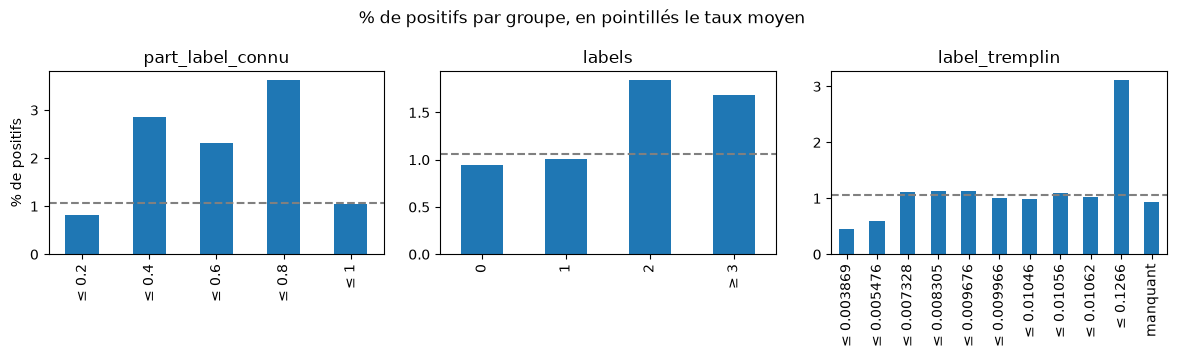

,renseignée,non nulle,AUC,% en bas,% en haut
part_label_connu,1.000,0.584,0.521,0.810,1.055
labels,1.000,0.701,0.537,0.942,1.683
label_tremplin,0.701,0.701,0.602,0.444,3.113


In [7]:
lab = par_cohorte(label)
graphiques(lab, lab.columns.drop("y"))
resume(lab)

In [8]:
sensibilite = {}
for m, n in [(10, 5), (100, 5), (1000, 5), (100, 3), (100, 8)]:
    t = lab if (m, n) == (100, 5) else par_cohorte(label, m=m, n=n)
    sensibilite[f"lissage {m}, {n} cohortes passées"] = auc(t["label_tremplin"], t["y"])
pd.Series(sensibilite, name="AUC de label_tremplin").round(3)

lissage 10, 5 cohortes passées      0.591
lissage 100, 5 cohortes passées     0.602
lissage 1000, 5 cohortes passées    0.594
lissage 100, 3 cohortes passées     0.591
lissage 100, 8 cohortes passées     0.606
Name: AUC de label_tremplin, dtype: float64

`label_tremplin` est l'une des variables les plus fortes, avec une AUC de 0,602 derrière les singles (0,614). Son décile le plus bas a 0,44 % de positifs, le plus haut 3,11 %. Les réglages vont de 0,591 à 0,606. 8 cohortes passées font un peu mieux que 5 (0,606 contre 0,602), un écart faible. On garde un lissage de 100 et 5 cohortes passées, le réglage choisi avant la correction de la cible.

## 5. Proximité des majors

Un artiste déjà au contact d'une major est sans doute repéré. On compte quatre façons de l'être.

- Sortir chez un label indépendant distribué par une major, avec un lien label distribution créé et commencé avant T0.
- Sortir chez un distributeur de major, un des labels Distributor retirés de la cible.
- Avoir une édition isolée chez une major, sur un disque à moins de la moitié en major.
- Être invité sur un disque de major.

In [9]:
pro = par_cohorte(proximite)
pd.DataFrame({
    "artistes concernés": (pro.drop(columns="y") > 0).sum(),
    "% de positifs si > 0": [100 * pro.loc[pro[c] > 0, "y"].mean() for c in pro.columns.drop("y")],
    "% de positifs sinon": [100 * pro.loc[pro[c] == 0, "y"].mean() for c in pro.columns.drop("y")],
}).round(2)

,artistes concernés,% de positifs si > 0,% de positifs sinon
label_distribue_major,1948,2.67,1.05
distributeur_major,113,17.70,1.05
edition_major_isolee,143,20.28,1.05
invite_major,244,11.89,1.05


Peu d'artistes sont concernés, mais le taux grimpe. Une édition isolée chez une major donne 20,28 % de positifs (143 artistes), contre 1,05 % sinon. Une sortie chez un distributeur de major donne 17,70 % (113 artistes). Être invité sur un disque de major donne 11,89 % (244 artistes). Un label distribué par une major fait bien moins (2,67 %, 1 948 artistes).

## 6. Réseau

Collaborer avec des artistes déjà en major, ou être lié à l'un d'eux par un lien member of band, ouvre peut-être des portes. Les collaborateurs viennent des crédits des sorties connues à T0, les liens de membres doivent être créés avant T0.

In [10]:
tardifs = []
for t0 in ENTRAINEMENT:
    population = cohorte(sorties, t0)
    liens = membres()
    liens = liens[liens["membre"].isin(population.index) | liens["groupe"].isin(population.index)].copy()
    liens["y"] = liens["membre"].map(population).fillna(liens["groupe"].map(population))
    liens["créé après T0"] = liens["creation"].dt.year >= t0
    tardifs.append(liens)
pd.concat(tardifs).groupby("y")["créé après T0"].mean().round(3)

y
False    0.580
True     0.652
Name: créé après T0, dtype: float64

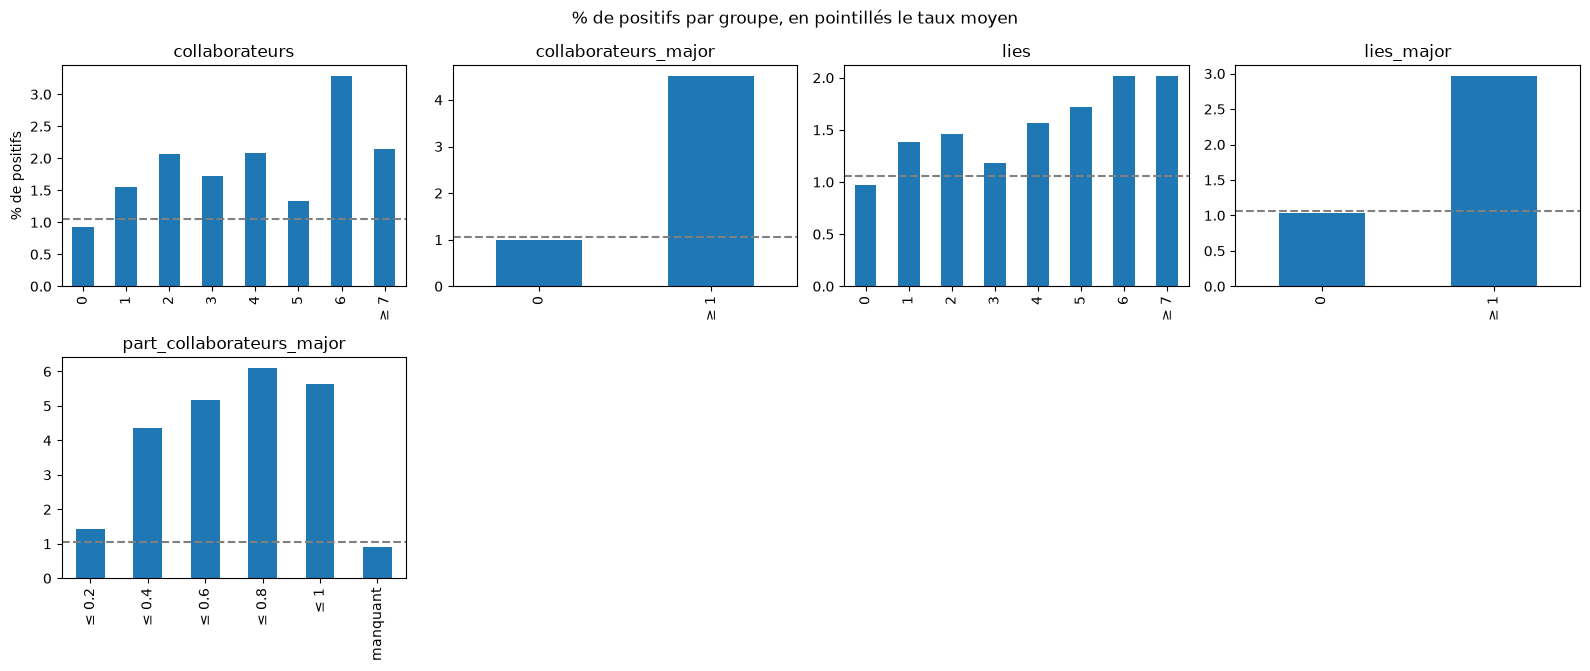

,renseignée,non nulle,AUC,% en bas,% en haut
collaborateurs,1.000,0.163,0.556,0.921,2.153
collaborateurs_major,1.000,0.020,0.533,0.988,4.516
lies,1.000,0.171,0.535,0.973,2.018
lies_major,1.000,0.012,0.511,1.036,2.969
part_collaborateurs_major,0.163,0.020,0.600,1.419,5.632


In [11]:
res = par_cohorte(reseau)
graphiques(res, res.columns.drop("y"))
resume(res)

65,2 % des liens de membres touchant un positif ont été créés après T0, contre 58,0 % pour les négatifs. D'où la règle des liens créés avant T0.

Avoir au moins un collaborateur déjà en major donne 4,52 % de positifs contre 0,99 % (AUC 0,533). Parmi les 16,3 % d'artistes qui ont des collaborateurs, la part déjà en major est le meilleur signal (AUC 0,600). Au-delà de 80 % de collaborateurs en major, on a 5,63 % de positifs. Les liens de membres apportent moins (AUC 0,535 et 0,511).

## 7. Profil

Le type (personne ou groupe) et le pays changent-ils les chances de signer ?

Le profil est celui d'aujourd'hui, la base n'en garde pas l'historique. Une fiche remplie après le succès ferait passer « profil complet » pour un signe de signature. On compare donc le signal des valeurs manquantes entre deux groupes. D'un côté les fiches modifiées après T0, de l'autre les fiches encore dans leur état de T0.

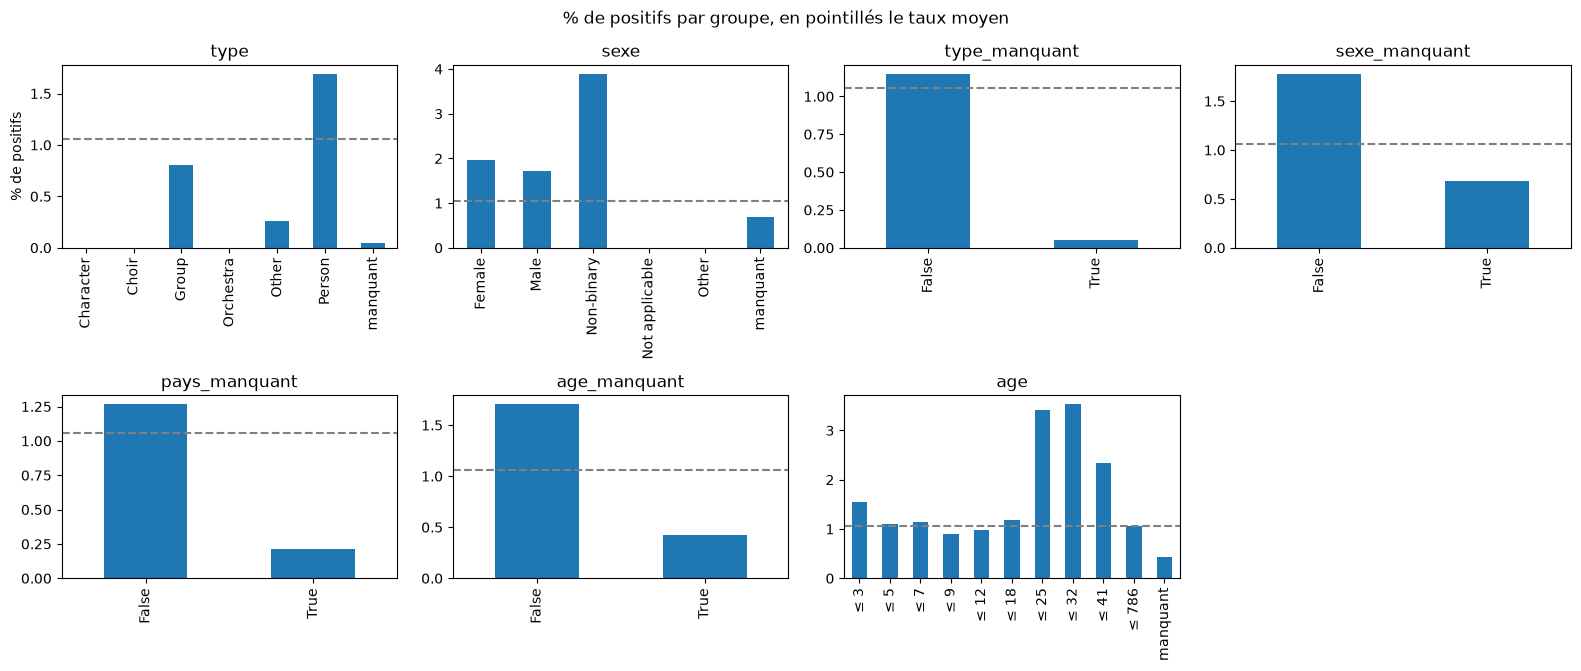

y
False    0.481
True     0.831
Name: fiche modifiée après T0, dtype: Float64


,toutes les fiches,fiche de T0,fiche modifiée après T0
type_manquant,0.460,0.438,0.491
pays_manquant,0.420,0.401,0.478
sexe_manquant,0.382,0.435,0.409
age_manquant,0.348,0.384,0.398
age,0.571,0.533,0.543


In [12]:
prf = par_cohorte(profil)
graphiques(prf, ["type", "sexe", "type_manquant", "sexe_manquant", "pays_manquant", "age_manquant", "age"])

modifiee = lire("artist", ["id", "last_updated"]).set_index("id")["last_updated"].dt.year
prf["fiche modifiée après T0"] = prf.index.get_level_values("artist").map(modifiee) >= prf.index.get_level_values("t0")
print(prf.groupby("y")["fiche modifiée après T0"].mean().round(3))

manquants = ["type_manquant", "pays_manquant", "sexe_manquant", "age_manquant", "age"]
groupes = {"toutes les fiches": prf, "fiche de T0": prf[~prf["fiche modifiée après T0"]], "fiche modifiée après T0": prf[prf["fiche modifiée après T0"]]}
pd.DataFrame({nom: [auc(g[c], g["y"]) for c in manquants] for nom, g in groupes.items()}, index=manquants).round(3)

83,1 % des positifs ont une fiche modifiée après T0, contre 48 % des négatifs. Le profil d'aujourd'hui des positifs n'est donc souvent plus celui de T0.

- Sexe et âge. Sur toutes les fiches, leurs manquants ont une AUC de 0,382 et 0,348, et l'âge de 0,571. C'est plus fort que dans chaque groupe pris à part, 0,384 à 0,435 pour les manquants, 0,533 et 0,543 pour l'âge. Une partie vient donc des fiches complétées après coup. On les écarte.
- Type et pays. Leur AUC sur toutes les fiches (0,460 et 0,420) reste entre celles des deux groupes, leur signal ne vient pas surtout des modifications. On les garde, avec leurs indicateurs de manquant. Sur le graphique, une personne passe plus souvent en major qu'un groupe.

## 8. Marché

Les majors signent peut-être plus dans certains pays. Le taux de passage en major du pays de l'artiste se calcule comme celui des labels, sur les 5 cohortes passées, lissé.

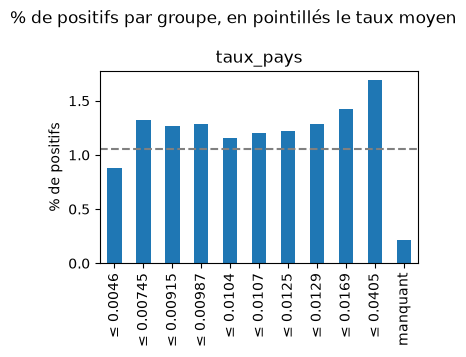

,renseignée,non nulle,AUC,% en bas,% en haut
taux_pays,0.802,0.802,0.533,0.875,1.69


In [13]:
mar = par_cohorte(marche)
graphiques(mar, ["taux_pays"])
resume(mar)

De 0,88 % de positifs dans le décile de pays le plus bas à 1,69 % dans le plus haut (AUC 0,533).

## 9. Statut en major vu de T0 et test anti-fuite

Une sortie connue à T0 peut passer en major après coup. Il suffit qu'on lui ajoute un label, ou qu'un lien rattache son label à une major, après T0. Les variables recalculent donc ce statut avec la base vue de T0 (`vue_de_t0`). Le premier tableau donne, sur les 3 ans avant T0, la part des sorties en major vues d'aujourd'hui mais pas de T0. Le second compare l'AUC des variables qui s'en servent, avec la base d'aujourd'hui ou vue de T0.

In [14]:
fuite = {}
for t0 in ENTRAINEMENT:
    aujourd_hui = recentes(sorties, t0)["major"]
    a_t0 = recentes(vues[t0], t0)["major"]
    fuite[t0] = {
        "en major vues d'aujourd'hui": aujourd_hui.sum(),
        "vues de T0": a_t0.sum(),
        "% en major seulement vues d'aujourd'hui": 100 * (aujourd_hui & ~a_t0).sum() / aujourd_hui.sum(),
    }
pd.DataFrame.from_dict(fuite, orient="index").round(1)

,en major vues d'aujourd'hui,vues de T0,% en major seulement vues d'aujourd'hui
2014,8324,3948,53.1
2015,10141,7053,30.9
2016,10649,8209,23.5
2017,11271,9122,19.7
2018,12642,10666,16.2


In [15]:
lignes = {}
for famille, colonne in [(label, "label_tremplin"), (marche, "taux_pays"), (reseau, "collaborateurs_major"), (proximite, "invite_major")]:
    aujourd_hui = pd.concat([cohorte(sorties, t0).rename("y").to_frame().join(famille(sorties, t0)) for t0 in ENTRAINEMENT])
    a_t0 = par_cohorte(famille)
    lignes[colonne] = {"AUC, base d'aujourd'hui": auc(aujourd_hui[colonne], aujourd_hui["y"]), "AUC, base vue de T0": auc(a_t0[colonne], a_t0["y"])}
pd.DataFrame(lignes).T.round(3)

,"AUC, base d'aujourd'hui","AUC, base vue de T0"
label_tremplin,0.613,0.602
taux_pays,0.554,0.533
collaborateurs_major,0.541,0.533
invite_major,0.509,0.505


En 2014, 53,1 % des sorties en major des 3 ans d'avant, vues d'aujourd'hui, ne l'étaient pas encore à T0. C'est encore 16,2 % en 2018. Avec la base d'aujourd'hui, les variables qui s'en servent gagnaient un signal venu du futur. Une fois la fuite corrigée, l'AUC de label_tremplin passe de 0,613 à 0,602. Celle de taux_pays passe de 0,554 à 0,533, celle de collaborateurs_major de 0,541 à 0,533.

On fausse ensuite la cohorte T0 = 2016 avec quatre sortes de fausses données.

- Des sorties en major après T0.
- Des sorties d'avant T0 ajoutées après T0.
- Des labels Sony sur des sorties connues, créés en 2016.
- Des liens qui rattachent leurs labels à Sony, créés en 2016.

Aucune variable ne doit changer, et elles doivent changer si ces labels et liens datent de la veille.

In [16]:
t0 = 2016
reelles = sorties[sorties["artist"].isin(cohorte(sorties, t0).index)]
futures = reelles.sample(5000, random_state=0).assign(annee=t0 + 1, major=True)
tardives = reelles[reelles["annee"] < t0].sample(5000, random_state=1).assign(date_ajout=pd.Timestamp(f"{t0}-06-01"), major=True)
faussees = pd.concat([sorties, futures, tardives])

connues = reelles[(reelles["annee"] < t0) & (reelles["date_ajout"].dt.year < t0)]
sony = HOLDINGS["Sony"][0]
faux_labels = connues[["release"]].sample(5000, random_state=2).assign(label=sony)
leurs_labels = connues[["release"]].merge(labels_des_sorties(), on="release")["label"].drop_duplicates().sample(1000, random_state=3)
tous_liens = liens_labels_crees()
sans_dates = tous_liens[(tous_liens["type_lien"] == "label ownership") & tous_liens["begin_date_year"].isna() & tous_liens["end_date_year"].isna()]
faux_liens = sans_dates.sample(1000, random_state=4).assign(entity0=sony, entity1=leurs_labels.values)


def variables_faussees(creation):
    """variables(faussees, t0) avec en plus les faux labels et les faux liens, créés à la date `creation`."""
    labels = pd.concat([labels_des_sorties(), faux_labels.assign(creation=creation)])
    liens = pd.concat([tous_liens, faux_liens.assign(creation=creation)])
    with patch.object(transformation, "labels_des_sorties", lambda: labels), patch.object(transformation, "liens_labels_crees", lambda: liens):
        transformation.arbre_connu.cache_clear()
        transformation.distribues_par_major.cache_clear()
        table = variables(faussees, t0)
    transformation.arbre_connu.cache_clear()
    transformation.distribues_par_major.cache_clear()
    return table.drop(columns="y")


reference = variables(sorties, t0).drop(columns="y")
pd.testing.assert_frame_equal(reference, variables_faussees(pd.Timestamp(f"{t0}-06-01")))
print(f"variables inchangées avec {len(futures) + len(tardives)} fausses sorties, {len(faux_labels)} faux labels et {len(faux_liens)} faux liens créés en {t0}")
veille = variables_faussees(pd.Timestamp(f"{t0 - 1}-12-31"))
differe = (reference != veille) & ~(reference.isna() & veille.isna())
print("variables qui changent si ces labels et liens datent de la veille :", list(reference.columns[differe.any()]))

variables inchangées avec 10000 fausses sorties, 5000 faux labels et 1000 faux liens créés en 2016


variables qui changent si ces labels et liens datent de la veille : ['part_label_connu', 'labels', 'label_tremplin', 'label_distribue_major', 'distributeur_major', 'edition_major_isolee', 'invite_major', 'collaborateurs_major', 'lies_major', 'part_collaborateurs_major', 'taux_pays']


## 10. Écartées sans calcul

- Notes et votes (`rating`, `rating_count` de `release_group_meta`). Moyenne d'aujourd'hui, sans date ni historique, donc inconnue à T0.
- Nombre de tags. Même problème, les votes sur les tags ne sont pas datés.
- Liens URL (réseaux sociaux, plateformes). Laissés au notebook 06, qui date leur création comme celle des liens de membres.

## 11. Table finale

On écarte le sexe et l'âge (partie 7), tout le reste est gardé. La table réunit les cohortes d'entraînement et de test.

In [17]:
table = pd.concat([variables(sorties, t0) for t0 in ENTRAINEMENT + [TEST]]).drop(columns=ECARTEES)
table.reset_index(names="artist").to_parquet("../data/features.parquet", index=False)
print(f"{table.shape[1] - 2} variables")
table.groupby("t0").size().rename("artistes")

30 variables


t0
2014    41081
2015    47075
2016    51359
2017    56812
2018    61480
2021    82372
Name: artistes, dtype: int64

## Sources

- Les notes de MusicBrainz, sans historique, https://musicbrainz.org/doc/Rating_System
- Les tags de MusicBrainz, sans date, https://musicbrainz.org/doc/Folksonomy_Tagging